# Customer Fraud Detection - Binary Classification

**Objective:** Predict whether a customer record is fraudulent or not using machine learning classification.

**Work flow:**

Data -> Preprocessing -> Encoding -> Train/Test Split -> Scaling -> SMOTE -> Models -> Evaluation -> Comparison -> Best Model


## 1. Import Required Library to load dataset file


In [ ]:

import pandas as pd


## 2. Load Dataset


In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('customer_analytics_dataset.csv')

In [5]:
df.shape

(5000, 13)

In [6]:
df.head()

,customer_id,age,gender,country,avg_order_value,total_orders,last_purchase,is_fraudulent,preferred_category,email_open_rate,customer_since,loyalty_score,churn_risk
0,CUST_8270,30,Female,Brazil,101.08,8,176,1,Beauty,25.6,2024-06-05,50,0.20
1,CUST_1860,53,Female,USA,90.39,10,88,0,Electronics,12.3,2024-02-19,37,0.34
2,CUST_6390,73,Male,Australia,83.28,6,203,0,Sports,NaN,2024-04-16,65,0.05
3,CUST_6191,30,Other,Japan,109.90,9,346,1,Electronics,42.9,2020-07-08,93,0.19
4,CUST_6734,29,Female,Canada,269.38,16,342,0,Fashion,5.3,2025-04-09,79,0.15


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         5000 non-null   object 
 1   age                 5000 non-null   int64  
 2   gender              5000 non-null   object 
 3   country             5000 non-null   object 
 4   avg_order_value     4750 non-null   float64
 5   total_orders        5000 non-null   int64  
 6   last_purchase       5000 non-null   int64  
 7   is_fraudulent       5000 non-null   int64  
 8   preferred_category  5000 non-null   object 
 9   email_open_rate     4750 non-null   float64
 10  customer_since      5000 non-null   object 
 11  loyalty_score       5000 non-null   int64  
 12  churn_risk          5000 non-null   float64
dtypes: float64(3), int64(5), object(5)
memory usage: 507.9+ KB


## 3. Basic EDA


In [12]:
df.columns

Index(['customer_id', 'age', 'gender', 'country', 'avg_order_value',
       'total_orders', 'last_purchase', 'is_fraudulent', 'preferred_category',
       'email_open_rate', 'customer_since', 'loyalty_score', 'churn_risk'],
      dtype='object')

In [14]:
df.isnull().sum()

customer_id             0
age                     0
gender                  0
country                 0
avg_order_value       250
total_orders            0
last_purchase           0
is_fraudulent           0
preferred_category      0
email_open_rate       250
customer_since          0
loyalty_score           0
churn_risk              0
dtype: int64

In [16]:
df['is_fraudulent'].value_counts()*100/5000

is_fraudulent
0    97.42
1     2.58
Name: count, dtype: float64

In [17]:
df.duplicated().sum()

np.int64(0)

In [19]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

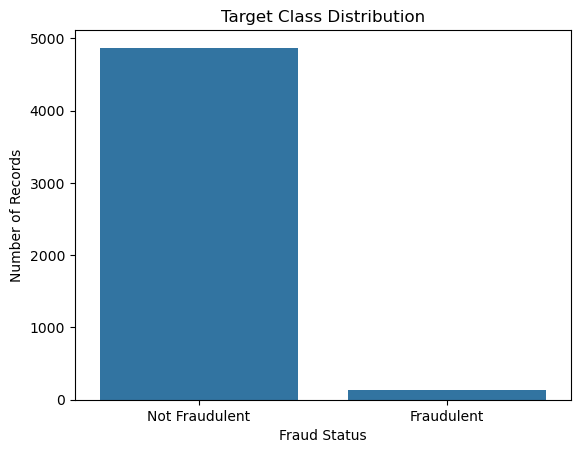

In [22]:
sns.countplot(x='is_fraudulent', data=df)

plt.title('Target Class Distribution')
plt.xlabel('Fraud Status')
plt.ylabel('Number of Records')
plt.xticks([0, 1], ['Not Fraudulent', 'Fraudulent'])

plt.show()


## 4. Remove Identifier Column


In [23]:
df['is_fraudulent'].value_counts(normalize=True)

is_fraudulent
0    0.9742
1    0.0258
Name: proportion, dtype: float64

In [ ]:
# customer_id removed because it is only an identifier and not a predictive feature.
df = df.drop(columns=['customer_id'])



## 5. Date Feature Engineering


In [24]:
df['last_purchase'] = pd.to_datetime(df['last_purchase'], errors='coerce')
df['customer_since'] = pd.to_datetime(df['customer_since'], errors='coerce')

In [25]:
# extracting year, month and date day as features
df['last_purchase_year'] = df['last_purchase'].dt.year
df['last_purchase_month'] = df['last_purchase'].dt.month
df['last_purchase_dayofweek'] = df['last_purchase'].dt.dayofweek

In [27]:
df.head(2)

,customer_id,age,gender,country,avg_order_value,total_orders,last_purchase,is_fraudulent,preferred_category,email_open_rate,customer_since,loyalty_score,churn_risk,last_purchase_year,last_purchase_month,last_purchase_dayofweek
0,CUST_8270,30,Female,Brazil,101.08,8,1970-01-01 00:00:00.000000176,1,Beauty,25.6,2024-06-05,50,0.20,1970,1,3
1,CUST_1860,53,Female,USA,90.39,10,1970-01-01 00:00:00.000000088,0,Electronics,12.3,2024-02-19,37,0.34,1970,1,3


In [28]:

df['customer_since_year'] = df['customer_since'].dt.year
df['customer_since_month'] = df['customer_since'].dt.month

In [31]:
df.head(3)

,customer_id,age,gender,country,avg_order_value,total_orders,last_purchase,is_fraudulent,preferred_category,email_open_rate,customer_since,loyalty_score,churn_risk,last_purchase_year,last_purchase_month,last_purchase_dayofweek,customer_since_year,customer_since_month
0,CUST_8270,30,Female,Brazil,101.08,8,1970-01-01 00:00:00.000000176,1,Beauty,25.6,2024-06-05,50,0.20,1970,1,3,2024,6
1,CUST_1860,53,Female,USA,90.39,10,1970-01-01 00:00:00.000000088,0,Electronics,12.3,2024-02-19,37,0.34,1970,1,3,2024,2
2,CUST_6390,73,Male,Australia,83.28,6,1970-01-01 00:00:00.000000203,0,Sports,NaN,2024-04-16,65,0.05,1970,1,3,2024,4


In [33]:
# Number of days since the customer joined
df['customer_tenure_days'] = (df['customer_since'].max() - df['customer_since']).dt.days

In [34]:
# Number of days since the latest purchase
last_reference = df['last_purchase'].max()
df['days_since_last_purchase'] = (last_reference - df['last_purchase']).dt.days

In [35]:
# Remove the original date columns after creating useful features
df = df.drop(columns=['last_purchase', 'customer_since'])

In [36]:
# Date columns converted into numerical features successfully.
df.head()

,customer_id,age,gender,country,avg_order_value,total_orders,is_fraudulent,preferred_category,email_open_rate,loyalty_score,churn_risk,last_purchase_year,last_purchase_month,last_purchase_dayofweek,customer_since_year,customer_since_month,customer_tenure_days,days_since_last_purchase
0,CUST_8270,30,Female,Brazil,101.08,8,1,Beauty,25.6,50,0.20,1970,1,3,2024,6,388,0
1,CUST_1860,53,Female,USA,90.39,10,0,Electronics,12.3,37,0.34,1970,1,3,2024,2,495,0
2,CUST_6390,73,Male,Australia,83.28,6,0,Sports,NaN,65,0.05,1970,1,3,2024,4,438,0
3,CUST_6191,30,Other,Japan,109.90,9,1,Electronics,42.9,93,0.19,1970,1,3,2020,7,1816,0
4,CUST_6734,29,Female,Canada,269.38,16,0,Fashion,5.3,79,0.15,1970,1,3,2025,4,80,0


## 6. Missing Values After Date Conversion


In [44]:
df.isnull().sum().sort_values(ascending=False)


avg_order_value             250
email_open_rate             250
customer_id                   0
churn_risk                    0
customer_tenure_days          0
customer_since_month          0
customer_since_year           0
last_purchase_dayofweek       0
last_purchase_month           0
last_purchase_year            0
loyalty_score                 0
age                           0
preferred_category            0
is_fraudulent                 0
total_orders                  0
country                       0
gender                        0
days_since_last_purchase      0
dtype: int64

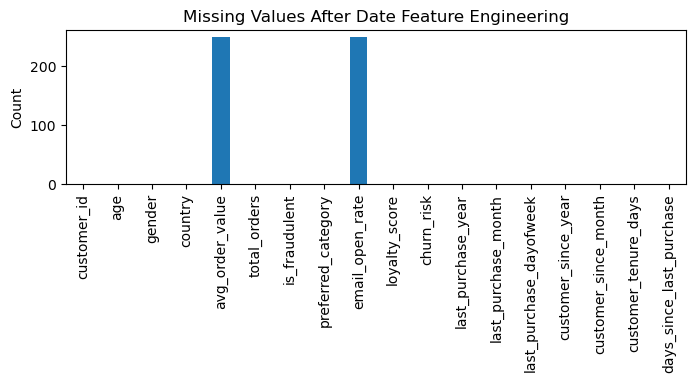

In [48]:
x = df.isnull().sum()
x.plot(kind="bar", figsize=(8, 2))
plt.title("Missing Values After Date Feature Engineering")
plt.ylabel("Count")
plt.show()

## 7. Outlier Detection


In [49]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_cols

['age',
 'avg_order_value',
 'total_orders',
 'is_fraudulent',
 'email_open_rate',
 'loyalty_score',
 'churn_risk',
 'customer_tenure_days',
 'days_since_last_purchase']

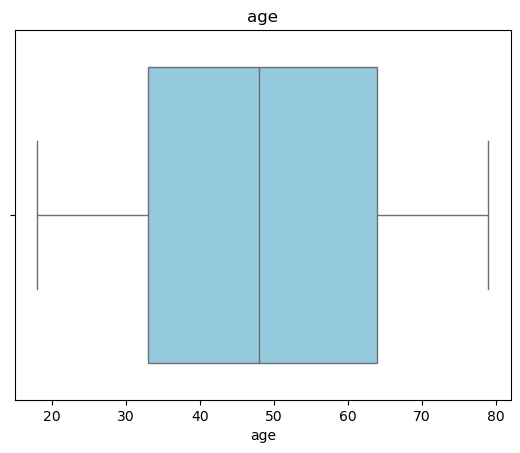

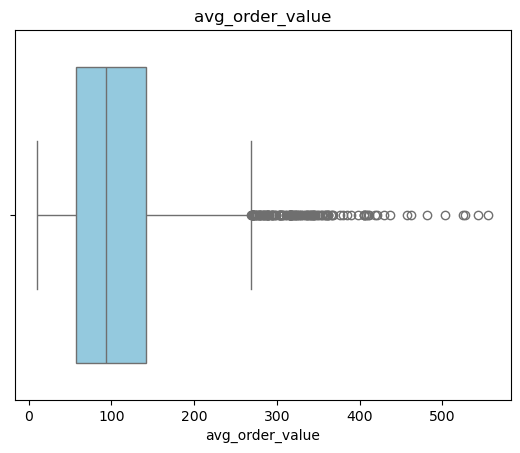

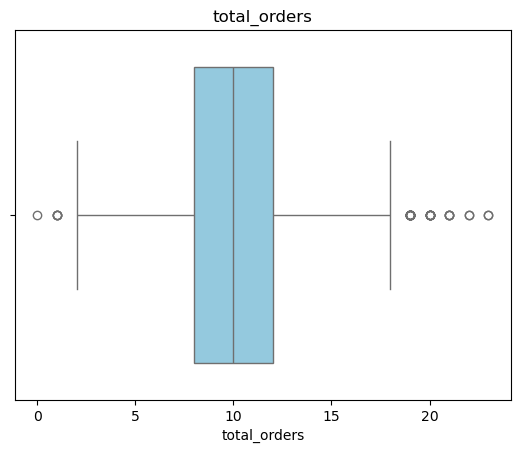

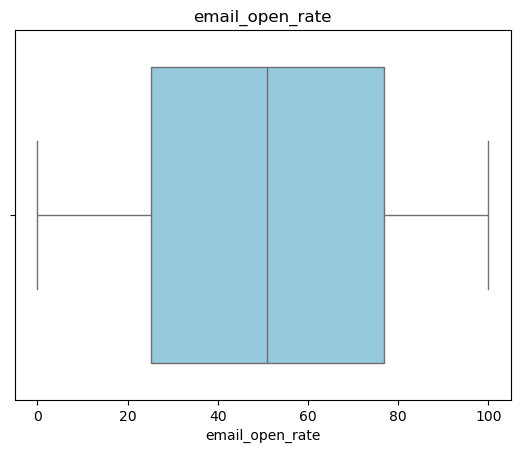

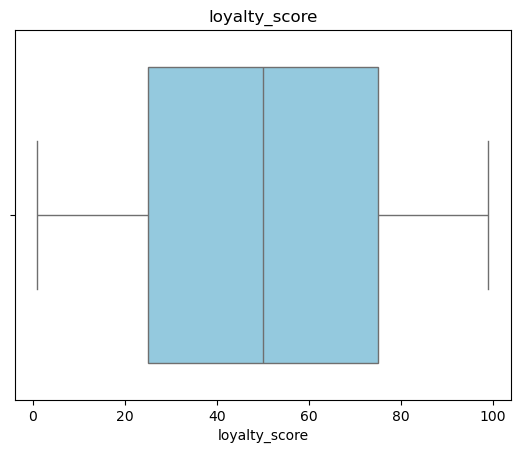

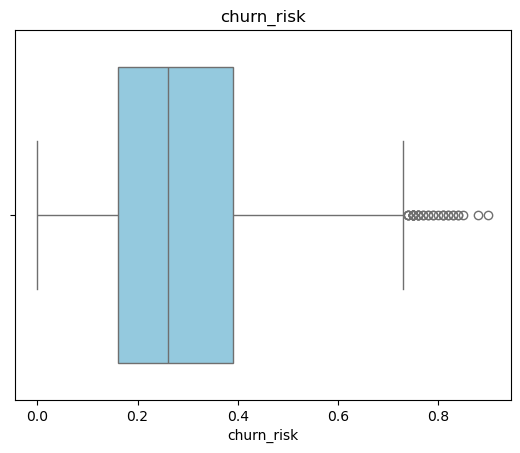

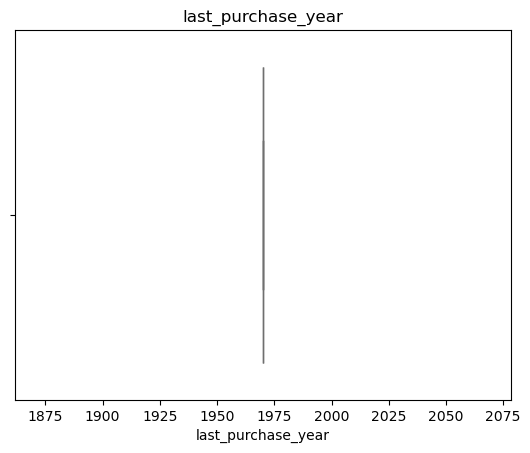

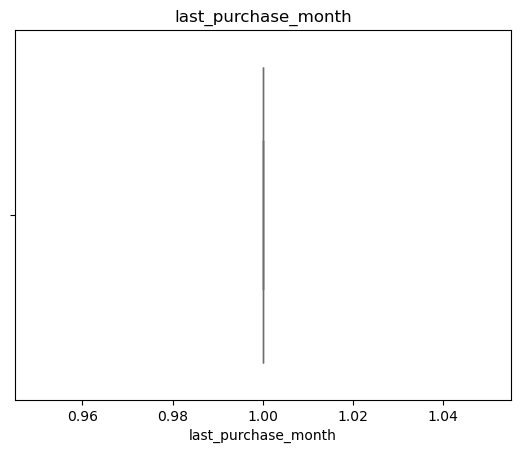

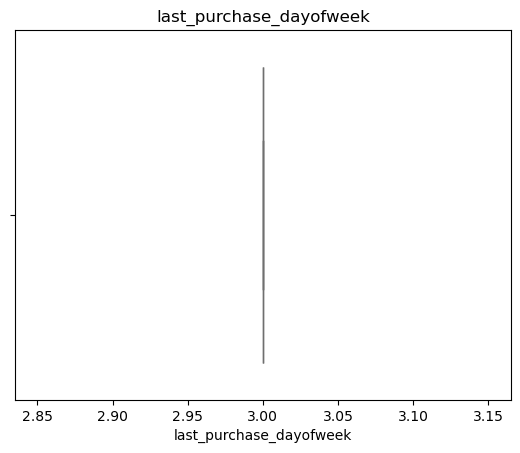

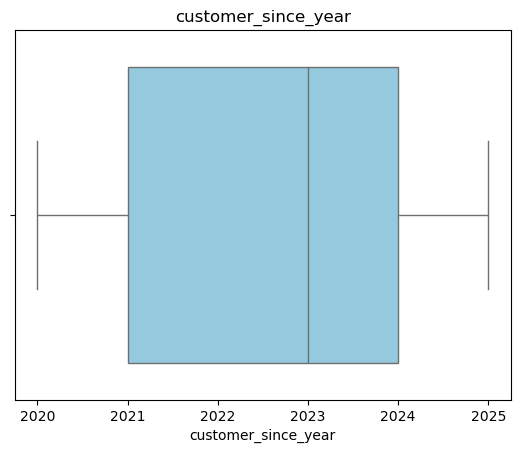

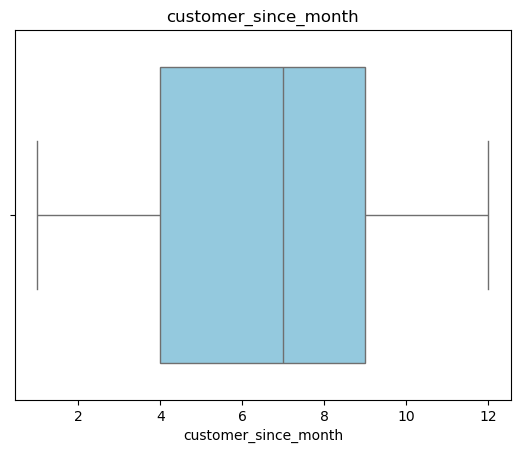

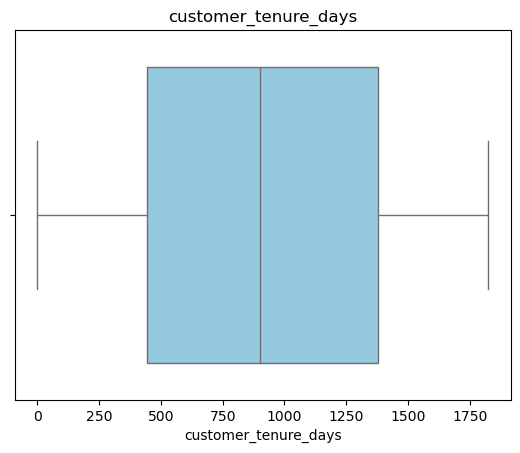

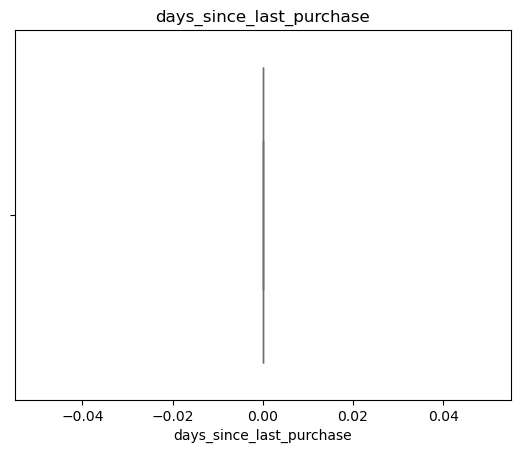

In [54]:
numeric_cols = df.select_dtypes(include='number').columns

numeric_cols = numeric_cols.drop('is_fraudulent')

for col in numeric_cols:
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(col)
    plt.show()


In [57]:
outlier_summary = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary[col] = outliers

outlier_df = pd.DataFrame(outlier_summary.items(), 
                          columns=['Column', 'Outlier Count'])

outlier_df.sort_values('Outlier Count', ascending=False)


,Column,Outlier Count
1,avg_order_value,137
2,total_orders,42
5,churn_risk,37
0,age,0
3,email_open_rate,0
4,loyalty_score,0
6,last_purchase_year,0
7,last_purchase_month,0
8,last_purchase_dayofweek,0
9,customer_since_year,0


## 8. Feature / Target Separation


In [60]:
X = df.drop(columns=['is_fraudulent'])
y = df['is_fraudulent']

In [61]:
y.shape

(5000,)

In [62]:
X.shape

(5000, 17)

In [64]:
# Fraud class ratio
y.value_counts(normalize=True)

is_fraudulent
0    0.9742
1    0.0258
Name: proportion, dtype: float64

## 9. Identify Numerical and Categorical Columns


In [66]:
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
categorical_cols

['customer_id', 'gender', 'country', 'preferred_category']

In [67]:

numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
numerical_cols


['age',
 'avg_order_value',
 'total_orders',
 'email_open_rate',
 'loyalty_score',
 'churn_risk',
 'customer_tenure_days',
 'days_since_last_purchase']

## 10. Data Preprocessing 

### Missing Values

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               5000 non-null   object 
 1   age                       5000 non-null   int64  
 2   gender                    5000 non-null   object 
 3   country                   5000 non-null   object 
 4   avg_order_value           4750 non-null   float64
 5   total_orders              5000 non-null   int64  
 6   is_fraudulent             5000 non-null   int64  
 7   preferred_category        5000 non-null   object 
 8   email_open_rate           4750 non-null   float64
 9   loyalty_score             5000 non-null   int64  
 10  churn_risk                5000 non-null   float64
 11  last_purchase_year        5000 non-null   int32  
 12  last_purchase_month       5000 non-null   int32  
 13  last_purchase_dayofweek   5000 non-null   int32  
 14  customer

In [68]:
df.isnull().sum().sort_values(ascending=False)

avg_order_value             250
email_open_rate             250
customer_id                   0
churn_risk                    0
customer_tenure_days          0
customer_since_month          0
customer_since_year           0
last_purchase_dayofweek       0
last_purchase_month           0
last_purchase_year            0
loyalty_score                 0
age                           0
preferred_category            0
is_fraudulent                 0
total_orders                  0
country                       0
gender                        0
days_since_last_purchase      0
dtype: int64

In [71]:
df['avg_order_value'] = df['avg_order_value'].fillna(df['avg_order_value'].median())

In [72]:
df['email_open_rate'] = df['email_open_rate'].fillna(df['email_open_rate'].mode()[0])


In [73]:
df.isnull().sum().sort_values(ascending=False)

customer_id                 0
age                         0
customer_tenure_days        0
customer_since_month        0
customer_since_year         0
last_purchase_dayofweek     0
last_purchase_month         0
last_purchase_year          0
churn_risk                  0
loyalty_score               0
email_open_rate             0
preferred_category          0
is_fraudulent               0
total_orders                0
avg_order_value             0
country                     0
gender                      0
days_since_last_purchase    0
dtype: int64

### Encoding

In [76]:
# Convert categorical columns into numbers
# One-Hot Encoding through pd.get_dummies()

df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

### Scaling
We chose **StandardScaler** because numerical features have different ranges and the dataset contains some outliers. StandardScaler puts the features on a similar scale and is less affected by extreme values than MinMaxScaler, which makes it a suitable choice for our preprocessing.

In [78]:
# Convert numerical features to a similar scale, with mean approximately 0 and standard deviation 1.
from sklearn.preprocessing import StandardScaler

In [79]:
scaler = StandardScaler()

In [80]:
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

## 11. Train/Test Split


In [83]:
from sklearn.model_selection import train_test_split


In [84]:
# Separate features and target
X = df.drop('is_fraudulent', axis=1)
y = df['is_fraudulent']

In [85]:
# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42, stratify=y)

In [86]:
# Check the shape of training and testing data
print("Training data:", X_train.shape, y_train.shape)
print("Testing data:", X_test.shape, y_test.shape)


Training data: (4000, 3836) (4000,)
Testing data: (1000, 3836) (1000,)


In [91]:
# Train target distribution
y_train.value_counts(normalize=True)

is_fraudulent
0    0.97425
1    0.02575
Name: proportion, dtype: float64

In [92]:
# Test target distribution:")
y_test.value_counts(normalize=True)

is_fraudulent
0    0.974
1    0.026
Name: proportion, dtype: float64

In [93]:
print('Testing shape:', X_test.shape, y_test.shape)
print('Train target distribution:')
print(y_train.value_counts(normalize=True))

Testing shape: (1000, 3836) (1000,)
Train target distribution:
is_fraudulent
0    0.97425
1    0.02575
Name: proportion, dtype: float64


In [94]:
print('Test target distribution:')
print(y_test.value_counts(normalize=True))

Test target distribution:
is_fraudulent
0    0.974
1    0.026
Name: proportion, dtype: float64


## 12. Class Imbalance Handling
SMOTE is used because dataset has many more non-fraud cases (97.425%) than fraud cases (2.575%). SMOTE helps create more fraud examples in the training data so the model can learn to detect fraud better. We used SMOTE only on the training data and kept the test data unchanged for a fair evaluation.


In [96]:
imbalance_ratio = y_train.value_counts().max() / y_train.value_counts().min()
print('Imbalance ratio:', round(imbalance_ratio, 2))

Imbalance ratio: 37.83


In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

In [ ]:
y_train.value_counts()

## 13. Define Models


In [105]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

In [ ]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'  )
}
print("Models are ready.")

## 14. Train All Models

In [ ]:
# Train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

print("All models trained successfully.")


## 15. Evaluate All Models

In [ ]:
# Make predictions
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Decision Tree")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred, zero_division=0))
print("Recall:", recall_score(y_test, dt_pred, zero_division=0))
print("F1-Score:", f1_score(y_test, dt_pred, zero_division=0))

print("\nRandom Forest")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred, zero_division=0))
print("Recall:", recall_score(y_test, rf_pred, zero_division=0))
print("F1-Score:", f1_score(y_test, rf_pred, zero_division=0))

print("\nXGBoost")
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred, zero_division=0))
print("Recall:", recall_score(y_test, xgb_pred, zero_division=0))
print("F1-Score:", f1_score(y_test, xgb_pred, zero_division=0))


## 16. Compare Initial Results

In [ ]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'XGBoost'],
    
    'Accuracy': [accuracy_score(y_test, dt_pred), accuracy_score(y_test, rf_pred), accuracy_score(y_test, xgb_pred) ],
    
    'Precision':[precision_score(y_test, dt_pred, zero_division=0), precision_score(y_test, rf_pred, zero_division=0),
        precision_score(y_test, xgb_pred, zero_division=0) ],
    
    'Recall': [recall_score(y_test, dt_pred, zero_division=0),recall_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, xgb_pred, zero_division=0)  ],
    
    'F1-Score': [f1_score(y_test, dt_pred, zero_division=0), f1_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, xgb_pred, zero_division=0)  ]    })

results


## 17. Tune All Models

### Tune - Decision Tree

In [117]:
from sklearn.model_selection import GridSearchCV

dt_params = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    scoring='f1',
    cv=5
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")
print(dt_grid.best_params_)


Best Decision Tree Parameters:
{'max_depth': None, 'min_samples_split': 5}


### Tune - Random Forest

In [118]:
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None]
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, scoring='f1', cv=5)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)


Best Random Forest Parameters:
{'max_depth': None, 'n_estimators': 200}


### Tune - XGBoost

In [119]:
xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1]
}

xgb_grid = GridSearchCV(XGBClassifier(random_state=42, eval_metric='logloss'),xgb_params,scoring='f1', cv=5)

xgb_grid.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_grid.best_params_)


Best XGBoost Parameters:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}


## 18. Evaluate Tuned Models

In [120]:
dt_tuned_pred = dt_grid.predict(X_test)
rf_tuned_pred = rf_grid.predict(X_test)
xgb_tuned_pred = xgb_grid.predict(X_test)


In [121]:
print("Tuned Decision Tree F1:",
      f1_score(y_test, dt_tuned_pred, zero_division=0))

print("Tuned Random Forest F1:",
      f1_score(y_test, rf_tuned_pred, zero_division=0))

print("Tuned XGBoost F1:",
      f1_score(y_test, xgb_tuned_pred, zero_division=0))


Tuned Decision Tree F1: 0.0
Tuned Random Forest F1: 0.0
Tuned XGBoost F1: 0.0


## 19. Tuned Models Comparison Table


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.935,0.046512,0.076923,0.057971
1,Random Forest,0.974,0.000000,0.000000,0.000000
2,XGBoost,0.965,0.000000,0.000000,0.000000


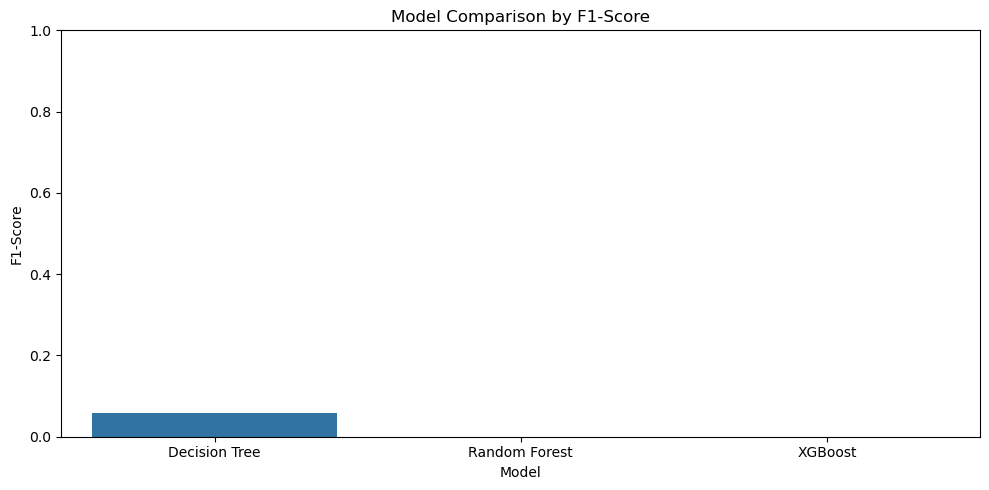

In [123]:
results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False).reset_index(drop=True)
display(results_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Model', y='F1-Score')
plt.title('Model Comparison by F1-Score')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## 20. Confusion Matrices and Classification Reports

Confusion Matrix ka simple meaning

Confusion matrix mein:

* True Negative (TN): Correctly identified as not fraud
* True Positive (TP): Correctly identified as fraud
* False Positive (FP): Not fraud, but predicted as fraud
* False Negative (FN): Fraud, but predicted as not fraud
* Fraud detection mein False Negative especially important hai, kyunki iska matlab hai ke actual fraud ko model ne miss kar diya.


### Decision Tree

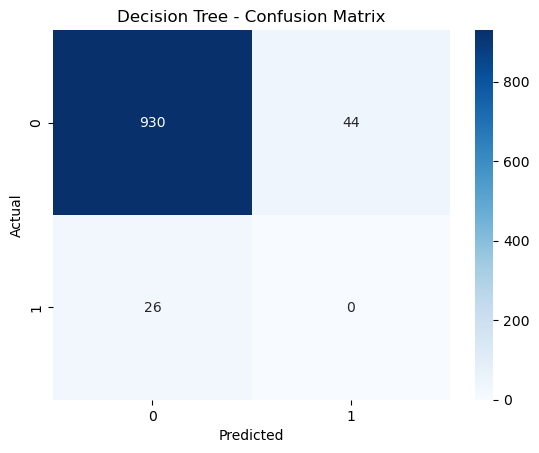

Decision Tree - Classification Report
              precision    recall  f1-score   support

           0       0.97      0.95      0.96       974
           1       0.00      0.00      0.00        26

    accuracy                           0.93      1000
   macro avg       0.49      0.48      0.48      1000
weighted avg       0.95      0.93      0.94      1000



In [127]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predictions
dt_pred = dt_grid.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, dt_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Classification Report
print("Decision Tree - Classification Report")
print(classification_report(y_test, dt_pred))


### Random Forest

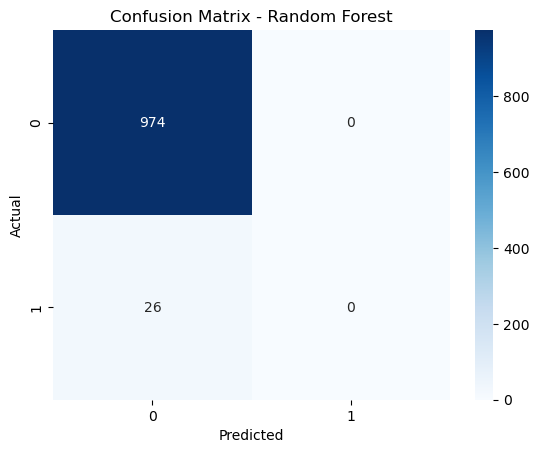

In [129]:
# Predictions
rf_pred = rf_grid.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()




In [133]:
# Classification Report
print("Random Forest Classification Report:")
print(classification_report(y_test,rf_pred, zero_division=0))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       974
           1       0.00      0.00      0.00        26

    accuracy                           0.97      1000
   macro avg       0.49      0.50      0.49      1000
weighted avg       0.95      0.97      0.96      1000



### XGBoost

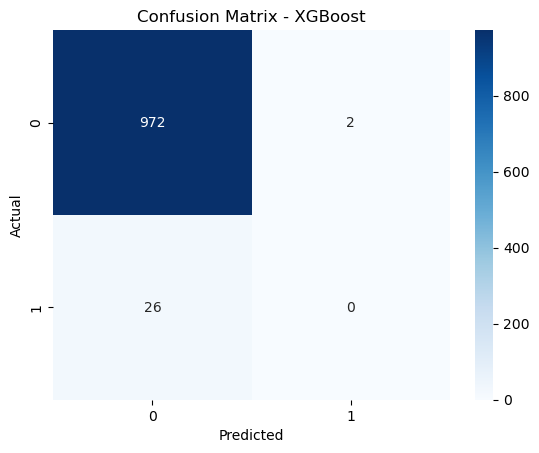

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       974
           1       0.00      0.00      0.00        26

    accuracy                           0.97      1000
   macro avg       0.49      0.50      0.49      1000
weighted avg       0.95      0.97      0.96      1000



In [134]:
# Predictions
xgb_pred = xgb_grid.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, xgb_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix - XGBoost')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Classification Report
print("XGBoost Classification Report:")
print(classification_report(y_test, xgb_pred))


# 21. Best Model Summary


In [125]:
tuned_results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'XGBoost'],
    
    'Accuracy': [
        accuracy_score(y_test, dt_tuned_pred),
        accuracy_score(y_test, rf_tuned_pred),
        accuracy_score(y_test, xgb_tuned_pred)
    ],
    
    'Precision': [
        precision_score(y_test, dt_tuned_pred, zero_division=0),
        precision_score(y_test, rf_tuned_pred, zero_division=0),
        precision_score(y_test, xgb_tuned_pred, zero_division=0)
    ],
    
    'Recall': [
        recall_score(y_test, dt_tuned_pred, zero_division=0),
        recall_score(y_test, rf_tuned_pred, zero_division=0),
        recall_score(y_test, xgb_tuned_pred, zero_division=0)
    ],
    
    'F1-Score': [
        f1_score(y_test, dt_tuned_pred, zero_division=0),
        f1_score(y_test, rf_tuned_pred, zero_division=0),
        f1_score(y_test, xgb_tuned_pred, zero_division=0)
    ]
})

tuned_results


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.930,0.0,0.0,0.0
1,Random Forest,0.974,0.0,0.0,0.0
2,XGBoost,0.972,0.0,0.0,0.0


In [135]:
best_model = tuned_results.loc[tuned_results['F1-Score'].idxmax()]

print("Best Model:", best_model['Model'])
print("Best F1-Score:", best_model['F1-Score'])


Best Model: Decision Tree
Best F1-Score: 0.0


## 22. Final Explanations


### Encoding Technique Used
**One-Hot Encoding** was used because categorical variables such as `gender`, `country`, and `preferred_category` are nominal and do not have any natural order. One-hot encoding converts them into machine-readable binary columns without introducing false numeric relationships.

### Scaling Technique Used
**StandardScaler** was used because it standardizes numerical features to mean 0 and variance 1. This is especially useful for models like Logistic Regression and helps keep the preprocessing pipeline consistent across models.

### SMOTE / Class Balancing
SMOTE was applied only when the training target classes were sufficiently imbalanced. This helps generate synthetic minority examples and improves model learning for fraud detection, especially for recall and F1-score.

### Required Models
- **Decision Tree**: Evaluated and compared
- **Random Forest**: Evaluated and compared
- **XGBoost**: Evaluated and compared if available in the environment


### Best Model Selection
The best model is selected based on **F1-Score**, because fraud detection is usually an imbalanced classification task and F1-score provides a balanced view of precision and recall.
